In [3]:
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "8"      # container limit is 8 CPUs (host reports 224)

import sys, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED)

PROJECT_ROOT = Path("/workspace/sic_final_project")
DATASET_DIR = PROJECT_ROOT / "Cats and Dogs Classification Dataset"
for d in ["src", "data/metadata", "data/splits", "results/figures", "results/metrics", "models"]:
    (PROJECT_ROOT / d).mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [4]:
%%writefile /workspace/sic_final_project/src/data_processing.py
"""Dataset scanning utilities (Phases 2-3)."""
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import pandas as pd
from PIL import Image


def scan_image(path: Path) -> dict:
    """Read one image's HEADER (cheap) and return its metadata.
    Never raises: failures are recorded in the 'error' column."""
    record = {
        "path": str(path), "label": path.parent.name, "extension": path.suffix.lower(),
        "file_size_kb": path.stat().st_size / 1024,
        "width": None, "height": None, "mode": None, "channels": None,
        "pil_format": None, "error": None,
    }
    try:
        with Image.open(path) as img:   # lazy: reads the header, does not decode pixels
            record.update(width=img.width, height=img.height,
                          mode=img.mode, pil_format=img.format)
            record["channels"] = len(img.getbands())
    except Exception as exc:
        record["error"] = f"{type(exc).__name__}: {exc}"[:120]
    return record


def build_metadata(dataset_dir: Path, n_workers: int = 8) -> pd.DataFrame:
    """Recursively scan dataset_dir and return one row per file."""
    files = sorted(p for p in Path(dataset_dir).rglob("*") if p.is_file())
    with ThreadPoolExecutor(max_workers=n_workers) as pool:
        rows = list(pool.map(scan_image, files, chunksize=64))
    return pd.DataFrame(rows)

Writing /workspace/sic_final_project/src/data_processing.py


In [5]:
import importlib, data_processing
importlib.reload(data_processing)

t0 = time.time()
df = data_processing.build_metadata(DATASET_DIR, n_workers=8)
print(f"Scanned {len(df):,} files in {time.time()-t0:.1f}s")

df.to_csv(PROJECT_ROOT / "data/metadata/metadata_raw.csv", index=False)   # saved for Phase 3
display(df.head())
print(df.dtypes)
print("\nFiles whose header could not be read:", df["error"].notna().sum())

/usr/local/lib/python3.10/dist-packages/PIL/TiffImagePlugin.py:900: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Scanned 24,998 files in 14.4s


,path,label,extension,file_size_kb,width,height,mode,channels,pil_format,error
0,/workspace/sic_final_project/Cats and Dogs Cla...,Cat,.jpg,11.926758,500,375,RGB,3,JPEG,None
1,/workspace/sic_final_project/Cats and Dogs Cla...,Cat,.jpg,16.472656,300,281,RGB,3,JPEG,None
2,/workspace/sic_final_project/Cats and Dogs Cla...,Cat,.jpg,34.551758,489,500,RGB,3,JPEG,None
3,/workspace/sic_final_project/Cats and Dogs Cla...,Cat,.jpg,30.004883,403,500,RGB,3,JPEG,None
4,/workspace/sic_final_project/Cats and Dogs Cla...,Cat,.jpg,25.726562,150,150,RGB,3,JPEG,None


path             object
label            object
extension        object
file_size_kb    float64
width             int64
height            int64
mode             object
channels          int64
pil_format       object
error            object
dtype: object

Files whose header could not be read: 0


Q6 - folders / classes found: ['Cat', 'Dog']

Q7/Q8 - images per class (before cleaning):
label
Cat    12499
Dog    12499
Name: count, dtype: int64

Q9 - class percentages:
label
Cat    50.0
Dog    50.0
Name: count, dtype: float64


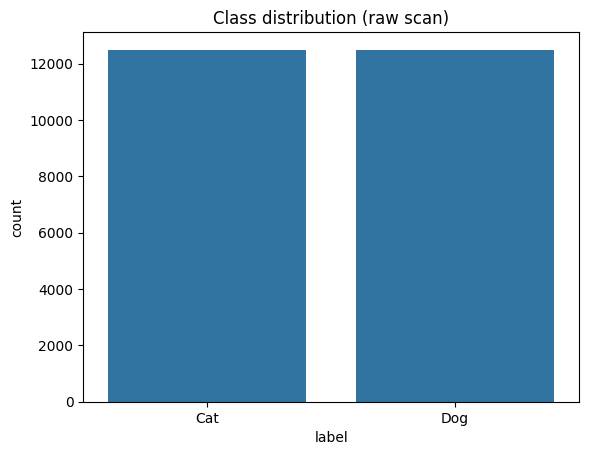

In [6]:
print("Q6 - folders / classes found:", sorted(df["label"].unique()))
counts = df["label"].value_counts()
print("\nQ7/Q8 - images per class (before cleaning):")
print(counts)
pct = (counts / counts.sum() * 100).round(2)
print("\nQ9 - class percentages:")
print(pct)
sns.countplot(data=df, x="label")
plt.title("Class distribution (raw scan)"); plt.show()

In [7]:
print("Q11 - file extensions:", df["extension"].value_counts().to_dict())
print("PIL-detected formats:", df["pil_format"].value_counts(dropna=False).to_dict())
print("Colour modes:", df["mode"].value_counts(dropna=False).to_dict())

ok = df[df["error"].isna()].copy()
ok["aspect_ratio"] = ok["width"] / ok["height"]
print("\nQ12 - dimension statistics (readable headers only):")
print(ok[["width", "height", "aspect_ratio", "file_size_kb"]]
      .agg(["min", "max", "mean", "median"]).round(2))

Q11 - file extensions: {'.jpg': 24998}
PIL-detected formats: {'JPEG': 24769, 'BMP': 173, 'GIF': 51, 'PNG': 4, 'PSD': 1}
Colour modes: {'RGB': 24931, 'P': 57, 'L': 5, 'CMYK': 3, 'RGBA': 2}

Q12 - dimension statistics (readable headers only):
         width  height  aspect_ratio  file_size_kb
min       4.00    4.00          0.31          0.34
max     500.00  500.00          5.94        957.35
mean    404.45  360.99          1.16         33.16
median  448.00  375.00          1.27         26.56


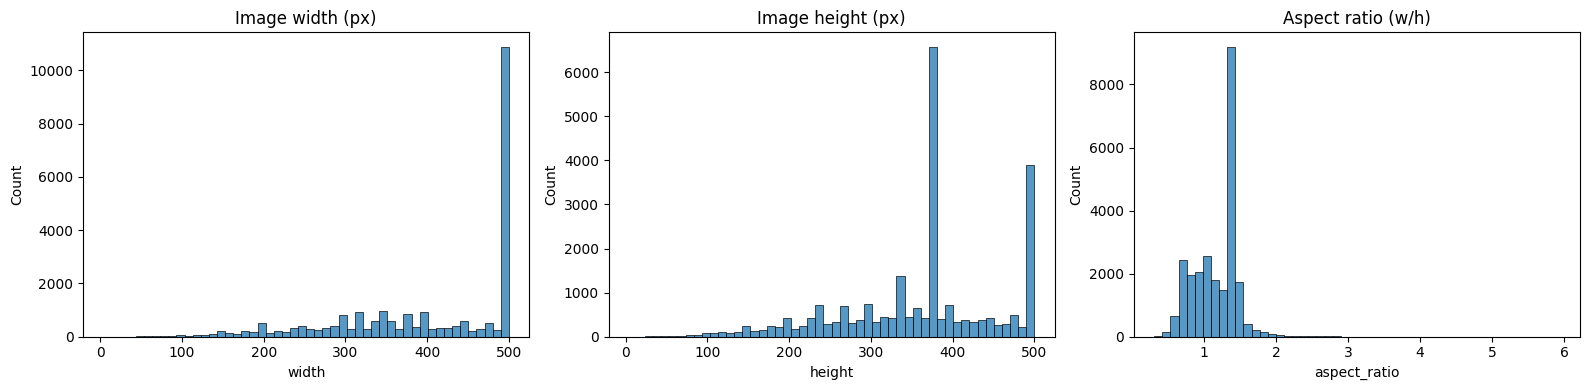

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(ok["width"], bins=50, ax=axes[0]);  axes[0].set_title("Image width (px)")
sns.histplot(ok["height"], bins=50, ax=axes[1]); axes[1].set_title("Image height (px)")
sns.histplot(ok["aspect_ratio"], bins=50, ax=axes[2]); axes[2].set_title("Aspect ratio (w/h)")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results/figures/02_dimension_distributions.png", dpi=120)
plt.show()

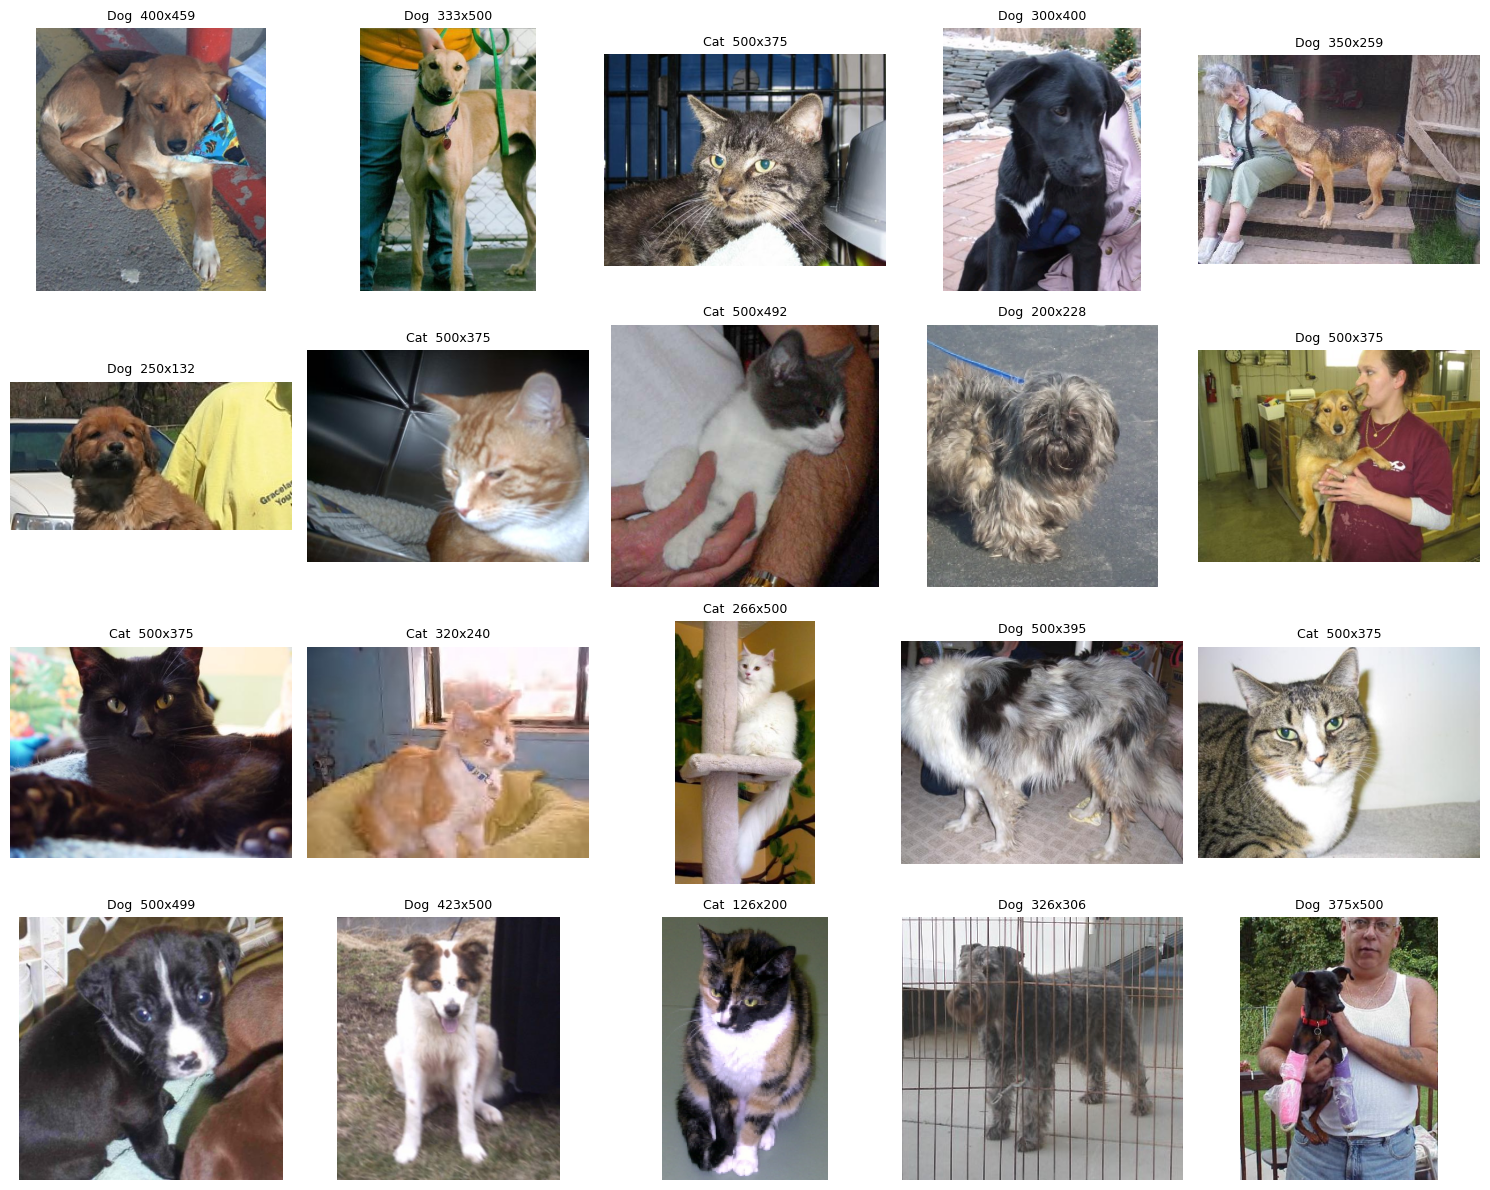

In [9]:
rng = np.random.default_rng(SEED)
sample = ok.iloc[rng.choice(len(ok), size=20, replace=False)]
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    with Image.open(row["path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"{row['label']}  {row['width']}x{row['height']}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results/figures/02_random_20.png", dpi=120)
plt.show()

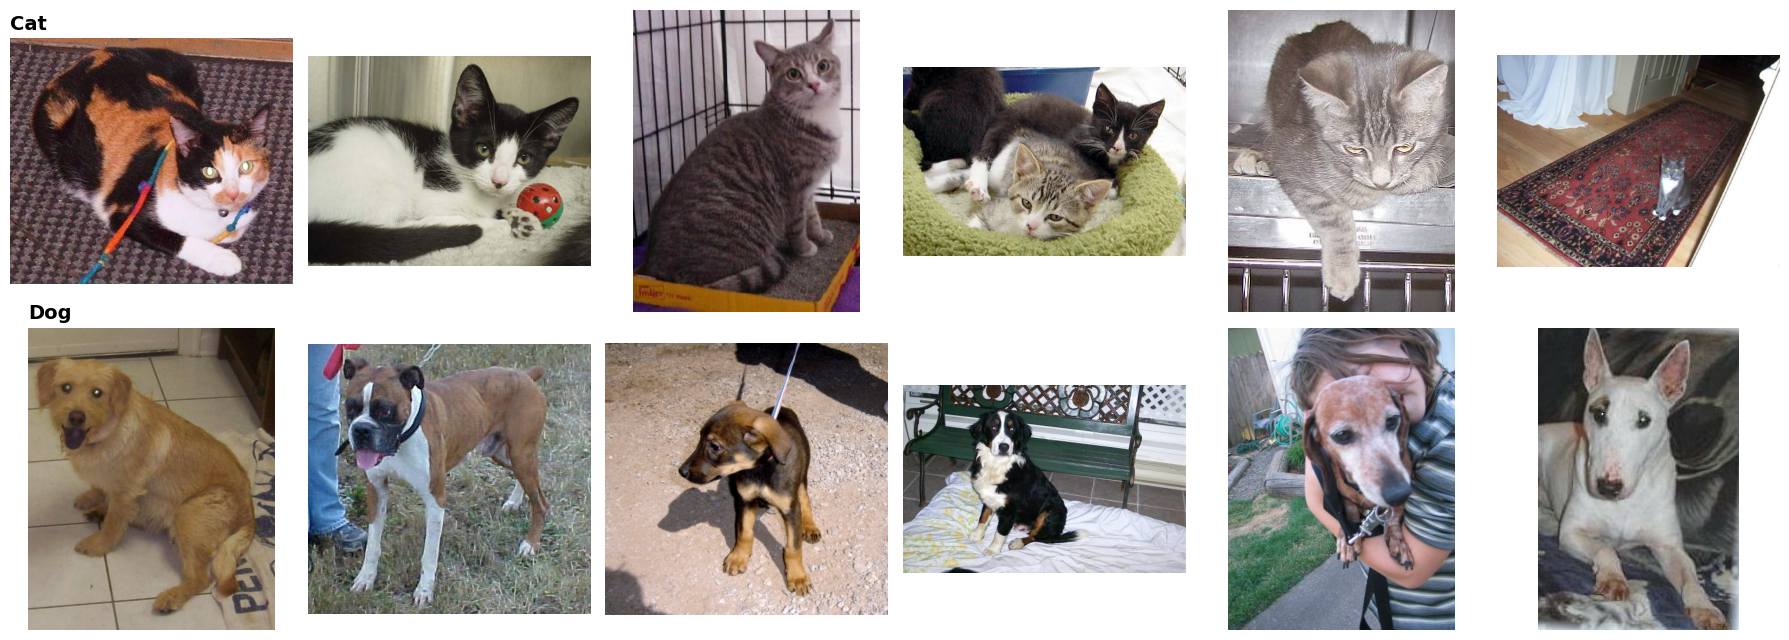

In [10]:
n = 6
fig, axes = plt.subplots(2, n, figsize=(3 * n, 6.5))
for r, cls in enumerate(["Cat", "Dog"]):
    picks = ok[ok["label"] == cls].sample(n, random_state=SEED)
    for c, (_, row) in enumerate(picks.iterrows()):
        with Image.open(row["path"]) as img:
            axes[r, c].imshow(img.convert("RGB"))
        axes[r, c].axis("off")
    axes[r, 0].set_title(cls, loc="left", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results/figures/02_cats_vs_dogs.png", dpi=120)
plt.show()